# 🧠 Stroke Risk Prediction - ML Zoomcamp Midterm Project
## End-to-End Classification Project following ML Zoomcamp Methodology (Modules 1 - 6)

---

## 1. Problem Definition & Business Understanding (Module 1: Intro & CRISP-DM)

### Clinical Context
A **stroke** (accidente cerebrovascular o ictus) occurs when blood supply to part of the brain is cut off or significantly reduced, preventing brain tissue from getting oxygen. According to the **World Health Organization (WHO)**, stroke is the second leading cause of death and a principal cause of long-term adult disability globally.

### CRISP-DM Framework Alignment:
1. **Business Understanding:** Enable healthcare providers and preventative health plans to identify high-risk patients before an acute stroke occurs. Interventions include antihypertensive therapy, glycemic management, anticoagulant prescription, and lifestyle coaching.
2. **Data Understanding:** Analyze 5,110 patient records covering demographic, medical condition, and behavioral variables.
3. **Data Preparation:** Clean text columns, isolate unique IDs, handle class imbalance, and impute missing BMI values without data leakage.
4. **Modeling:** Train and compare multiple algorithm families: **Logistic Regression**, **Decision Trees**, **Random Forest**, and **XGBoost**.
5. **Evaluation:** Use metrics tailored for severe class imbalance (ROC-AUC, PR-AUC, Confusion Matrix, Precision-Recall tradeoff, and K-Fold Cross-Validation).
6. **Deployment (Module 5):** Package the winning model into a standalone `train.py` script, expose a FastAPI web service in `predict.py`, and containerize with Docker.


## 2. Environment Setup & Library Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mutual_info_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Styling configurations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
%matplotlib inline

print("Libraries imported successfully!")


Libraries imported successfully!


## 3. Data Loading & Preparation (Module 3: Classification)

Following the ML Zoomcamp data preparation guidelines:
- Load data from `data/healthcare-dataset-stroke-data.csv`.
- Standardize all column names to lower snake_case: `df.columns = df.columns.str.lower().str.replace(' ', '_')`.
- Remove non-predictive identifiers (`id`).
- Normalize categorical string values: lowercasing and replacing spaces with underscores.
- Inspect missing values and cardinality of categorical features.


In [2]:
df = pd.read_csv('data/healthcare-dataset-stroke-data.csv')
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.head()


Dataset shape: 5110 rows, 12 columns



,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
# Column name standardization
df.columns = df.columns.str.lower().str.replace(' ', '_')
df = df.drop(columns=['id'])

categorical_cols = ['gender', 'ever_married', 'work_type', 'residence_type', 'smoking_status']
numerical_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

# Standardize string values in categorical columns
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip().str.lower().str.replace(' ', '_')

# Harmonize the single 'other' gender row to majority 'female'
df['gender'] = df['gender'].replace({'other': 'female'})

print("Missing values per column:")
print(df.isnull().sum())
print("\nUnique values per categorical column:")
print(df[categorical_cols].nunique())


Missing values per column:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Unique values per categorical column:
gender            2
ever_married      2
work_type         5
residence_type    2
smoking_status    4
dtype: int64


## 4. Setting up the Validation Framework (Module 3.3)

We use a **60% / 20% / 20%** split:
- 80% Full Train (`df_full_train`), 20% Test (`df_test`).
- Full Train is further split into 75% Train (`df_train`) and 25% Validation (`df_val`).
- We apply **stratification** on `stroke` to preserve the ~4.87% positive class proportion across all partitions.
- **Preventing Data Leakage:** The 201 missing values in `bmi` are imputed using the **median calculated exclusively on `df_train`**.


In [4]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['stroke']
)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42, stratify=df_full_train['stroke']
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Calculate median BMI on train set only (NO data leakage)
bmi_median_train = float(df_train['bmi'].median())
print(f"Train median BMI (for imputation): {bmi_median_train:.2f}")

for split_df in [df_train, df_val, df_test]:
    split_df['bmi'] = split_df['bmi'].fillna(bmi_median_train)

y_train = df_train['stroke'].values
y_val = df_val['stroke'].values
y_test = df_test['stroke'].values

df_train_features = df_train.drop(columns=['stroke'])
df_val_features = df_val.drop(columns=['stroke'])
df_test_features = df_test.drop(columns=['stroke'])

print(f"Train size: {len(df_train_features)} (Stroke count: {y_train.sum()} | {y_train.mean():.2%})")
print(f"Val size:   {len(df_val_features)} (Stroke count: {y_val.sum()} | {y_val.mean():.2%})")
print(f"Test size:  {len(df_test_features)} (Stroke count: {y_test.sum()} | {y_test.mean():.2%})")


Train median BMI (for imputation): 28.10
Train size: 3066 (Stroke count: 149 | 4.86%)
Val size:   1022 (Stroke count: 50 | 4.89%)
Test size:  1022 (Stroke count: 50 | 4.89%)


## 5. Exploratory Data Analysis (EDA) & Feature Importance (Modules 3.4 - 3.7)

### 5.1 Target Variable Distribution
We inspect the stroke distribution on the training set to quantify the class imbalance.


/tmp/ipykernel_45849/2706573514.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='stroke', data=eda_df, palette=['#4C72B0', '#C44E52'])


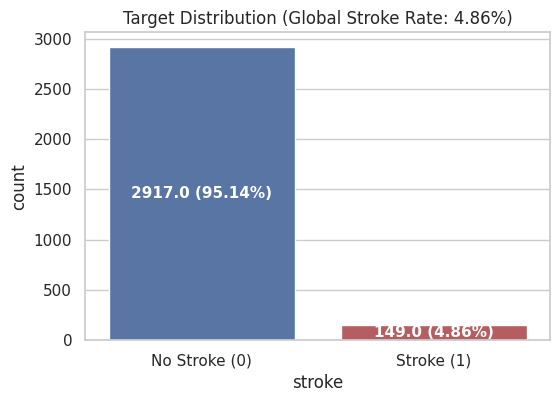

In [5]:
eda_df = df_train.copy()
global_stroke_rate = eda_df['stroke'].mean()

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='stroke', data=eda_df, palette=['#4C72B0', '#C44E52'])
plt.title(f'Target Distribution (Global Stroke Rate: {global_stroke_rate:.2%})')
plt.xticks([0, 1], ['No Stroke (0)', 'Stroke (1)'])
for p in ax.patches:
    ax.annotate(f"{p.get_height()} ({p.get_height()/len(eda_df):.2%})",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.show()


### 5.2 Feature Importance: Stroke Rate, Difference & Risk Ratio (Module 3.5)

In **Module 3.5**, Alexey Grigorev introduces **Risk Ratio** and **Difference**:
- **Difference:** `diff = group_mean - global_mean`.
  - `diff > 0`: Group is more likely to suffer a stroke than average.
  - `diff < 0`: Group is less likely to suffer a stroke than average.
- **Risk Ratio:** `risk = group_mean / global_mean`.
  - `risk > 1`: Higher risk compared to baseline.
  - `risk < 1`: Lower risk compared to baseline.


In [6]:
risk_tables = {}
features_for_risk = categorical_cols + ['hypertension', 'heart_disease']

for col in features_for_risk:
    df_group = eda_df.groupby(col)['stroke'].agg(['count', 'mean'])
    df_group['diff'] = df_group['mean'] - global_stroke_rate
    df_group['risk_ratio'] = df_group['mean'] / global_stroke_rate
    risk_tables[col] = df_group
    print(f"=== Feature: {col.upper()} ===")
    print(df_group.round(4))
    print()


=== Feature: GENDER ===
        count    mean    diff  risk_ratio
gender                                   
female   1824  0.0466 -0.0020      0.9589
male     1242  0.0515  0.0029      1.0603

=== Feature: EVER_MARRIED ===
              count    mean    diff  risk_ratio
ever_married                                   
no             1029  0.0185 -0.0301      0.3799
yes            2037  0.0638  0.0152      1.3132

=== Feature: WORK_TYPE ===
               count    mean    diff  risk_ratio
work_type                                       
children         421  0.0024 -0.0462      0.0489
govt_job         388  0.0541  0.0055      1.1137
never_worked       7  0.0000 -0.0486      0.0000
private         1760  0.0506  0.0020      1.0406
self-employed    490  0.0776  0.0290      1.5958

=== Feature: RESIDENCE_TYPE ===
                count    mean    diff  risk_ratio
residence_type                                   
rural            1504  0.0459 -0.0027      0.9440
urban            1562  0.0512  

### 5.3 Feature Importance: Mutual Information (Module 3.6)

Mutual Information measures how much information a categorical variable gives about the target `stroke`.


/tmp/ipykernel_45849/3894212825.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mi_scores.values, y=mi_scores.index, palette='viridis')


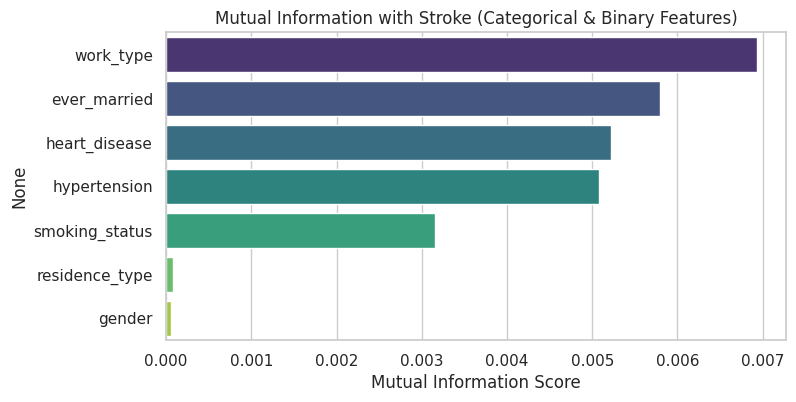

Mutual Information Scores:
work_type         0.0069
ever_married      0.0058
heart_disease     0.0052
hypertension      0.0051
smoking_status    0.0032
residence_type    0.0001
gender            0.0001
dtype: float64


In [7]:
def calculate_mi(series):
    return mutual_info_score(series, eda_df['stroke'])

mi_scores = eda_df[features_for_risk].apply(calculate_mi).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=mi_scores.values, y=mi_scores.index, palette='viridis')
plt.title('Mutual Information with Stroke (Categorical & Binary Features)')
plt.xlabel('Mutual Information Score')
plt.show()

print("Mutual Information Scores:")
print(mi_scores.round(4))


### 5.4 Feature Importance: Correlation (Module 3.7)

We analyze linear correlation between numerical features and `stroke`.


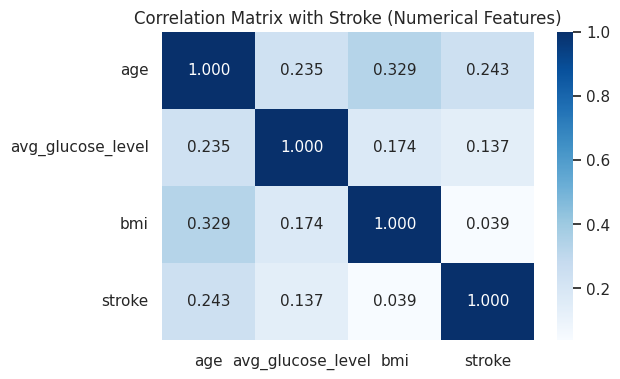

Correlation with stroke:
stroke               1.0000
age                  0.2425
avg_glucose_level    0.1373
bmi                  0.0385
Name: stroke, dtype: float64


In [8]:
num_corr = eda_df[['age', 'avg_glucose_level', 'bmi', 'stroke']].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(num_corr, annot=True, fmt='.3f', cmap='Blues', cbar=True)
plt.title('Correlation Matrix with Stroke (Numerical Features)')
plt.show()

print("Correlation with stroke:")
print(num_corr['stroke'].sort_values(ascending=False).round(4))


## 6. One-Hot Encoding with DictVectorizer (Module 3.8)

We fit `DictVectorizer(sparse=False)` on the training partition and transform validation and test partitions.


In [9]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train_features.to_dict(orient='records')
val_dicts = df_val_features.to_dict(orient='records')
test_dicts = df_test_features.to_dict(orient='records')

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

feature_names = dv.get_feature_names_out()
print(f"Total encoded features: {len(feature_names)}")
print("Engineered feature names:", list(feature_names))


Total encoded features: 20
Engineered feature names: ['age', 'avg_glucose_level', 'bmi', 'ever_married=no', 'ever_married=yes', 'gender=female', 'gender=male', 'heart_disease', 'hypertension', 'residence_type=rural', 'residence_type=urban', 'smoking_status=formerly_smoked', 'smoking_status=never_smoked', 'smoking_status=smokes', 'smoking_status=unknown', 'work_type=children', 'work_type=govt_job', 'work_type=never_worked', 'work_type=private', 'work_type=self-employed']


## 7. Model 1: Logistic Regression & Model Interpretation (Modules 3.9 - 3.11)

We train Logistic Regression with balanced class weights to compensate for the 95:5 class imbalance and tune regularization hyperparameter `C`.


In [10]:
c_values = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
lr_results = []

for c in c_values:
    lr = LogisticRegression(
        C=c,
        solver='liblinear',
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )
    lr.fit(X_train, y_train)
    val_probs = lr.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, val_probs)
    pr_auc = average_precision_score(y_val, val_probs)
    lr_results.append({'C': c, 'Val ROC-AUC': auc, 'Val PR-AUC': pr_auc})

df_lr_res = pd.DataFrame(lr_results).sort_values(by='Val ROC-AUC', ascending=False)
print("--- Logistic Regression Regularization Tuning ---")
print(df_lr_res.to_string(index=False))

best_lr_c = df_lr_res.iloc[0]['C']
best_lr_auc = df_lr_res.iloc[0]['Val ROC-AUC']


--- Logistic Regression Regularization Tuning ---
     C  Val ROC-AUC  Val PR-AUC
 0.500     0.837737    0.170442
10.000     0.837510    0.167191
 1.000     0.837490    0.166909
 5.000     0.837469    0.166957
 0.100     0.837407    0.173760
 0.010     0.828066    0.171400
 0.001     0.804918    0.157301


### Model Interpretation: Weights and Coefficients (Module 3.11)


/tmp/ipykernel_45849/3608021619.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=coefficients.values, y=coefficients.index, palette='coolwarm')


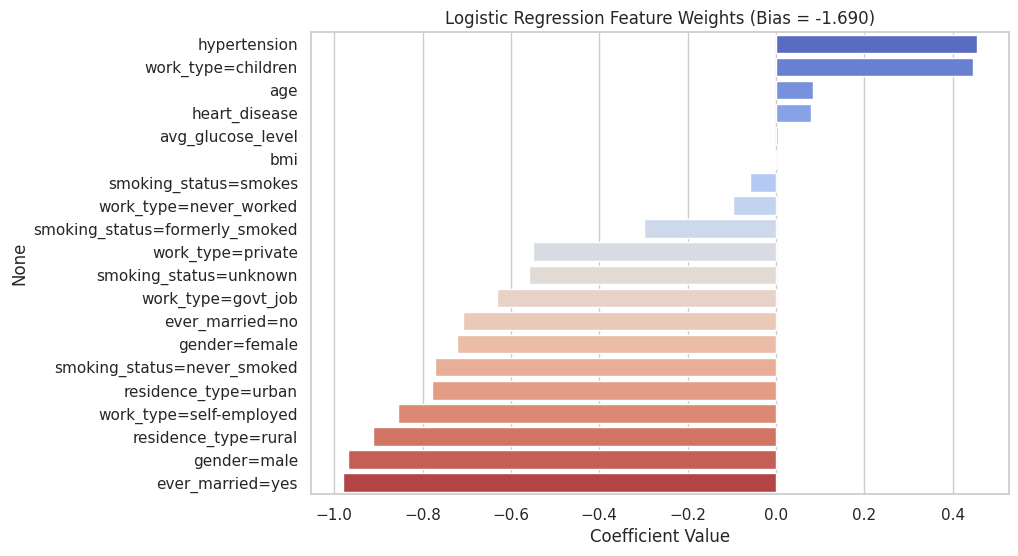

Bias (Intercept): -1.6896

Top Positive Coefficients (increase stroke probability):
hypertension          0.455145
work_type=children    0.445981
age                   0.082807
heart_disease         0.079514
avg_glucose_level     0.005233
dtype: float64

Top Negative Coefficients (decrease stroke probability):
residence_type=urban      -0.778529
work_type=self-employed   -0.855810
residence_type=rural      -0.911119
gender=male               -0.968569
ever_married=yes          -0.980246
dtype: float64


In [11]:
best_lr = LogisticRegression(C=best_lr_c, solver='liblinear', class_weight='balanced', random_state=42)
best_lr.fit(X_train, y_train)

coefficients = pd.Series(best_lr.coef_[0], index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=coefficients.values, y=coefficients.index, palette='coolwarm')
plt.title(f'Logistic Regression Feature Weights (Bias = {best_lr.intercept_[0]:.3f})')
plt.xlabel('Coefficient Value')
plt.show()

print(f"Bias (Intercept): {best_lr.intercept_[0]:.4f}")
print("\nTop Positive Coefficients (increase stroke probability):")
print(coefficients.head(5))
print("\nTop Negative Coefficients (decrease stroke probability):")
print(coefficients.tail(5))


## 8. Evaluation Metrics Deep Dive (Module 4)

### 8.1 Accuracy & The Dummy Model Baseline (Module 4.2)
Why accuracy is misleading on imbalanced datasets:
A dummy model that predicts **0 (No Stroke) for every patient** achieves an accuracy of **95.1%** despite catching **0% of stroke cases**!


In [12]:
# Dummy baseline: predict 0 for all
y_dummy = np.zeros(len(y_val))
dummy_accuracy = accuracy_score(y_val, y_dummy)

# Model accuracy at threshold 0.5
lr_val_probs = best_lr.predict_proba(X_val)[:, 1]
model_acc_05 = accuracy_score(y_val, lr_val_probs >= 0.5)

print(f"Dummy Model Accuracy (all 0s): {dummy_accuracy:.4f} ({dummy_accuracy*100:.2f}%)")
print(f"Logistic Regression Accuracy (threshold 0.5): {model_acc_05:.4f} ({model_acc_05*100:.2f}%)")

# Accuracy across thresholds
thresholds = np.linspace(0.1, 0.9, 9)
acc_scores = [accuracy_score(y_val, lr_val_probs >= t) for t in thresholds]
df_acc = pd.DataFrame({'threshold': thresholds, 'accuracy': acc_scores})
print("\nAccuracy across probability thresholds:")
print(df_acc.to_string(index=False))


Dummy Model Accuracy (all 0s): 0.9511 (95.11%)
Logistic Regression Accuracy (threshold 0.5): 0.7534 (75.34%)

Accuracy across probability thresholds:
 threshold  accuracy
       0.1  0.379648
       0.2  0.512720
       0.3  0.604697
       0.4  0.680039
       0.5  0.753425
       0.6  0.795499
       0.7  0.838552
       0.8  0.891389
       0.9  0.941292


### 8.2 Confusion Matrix, Precision & Recall (Modules 4.3 & 4.4)

- **Precision:** `TP / (TP + FP)` - When the model predicts stroke, how often is it right?
- **Recall:** `TP / (TP + FN)` - Of all actual stroke cases, what fraction did we detect?


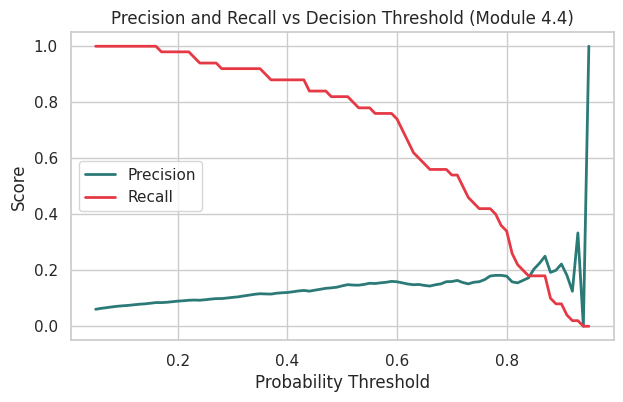

In [13]:
thresholds_pr = np.linspace(0.05, 0.95, 91)
precisions = []
recalls = []

for t in thresholds_pr:
    pred_pos = (lr_val_probs >= t)
    tp = (pred_pos & (y_val == 1)).sum()
    fp = (pred_pos & (y_val == 0)).sum()
    fn = ((~pred_pos) & (y_val == 1)).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 1.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precisions.append(p)
    recalls.append(r)

plt.figure(figsize=(7, 4))
plt.plot(thresholds_pr, precisions, label='Precision', color='#2B7A78', lw=2)
plt.plot(thresholds_pr, recalls, label='Recall', color='#E63946', lw=2)
plt.title('Precision and Recall vs Decision Threshold (Module 4.4)')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()


### 8.3 ROC Curve vs Random Baseline & Ideal Model (Module 4.5)

As taught in **Module 4.5**, we compare our model's ROC curve against:
1. **The Random Model:** Coin-flip classifier (diagonal line from (0,0) to (1,1)).
2. **The Ideal Model:** Perfect ordering where all stroke cases are ranked higher than non-stroke cases.


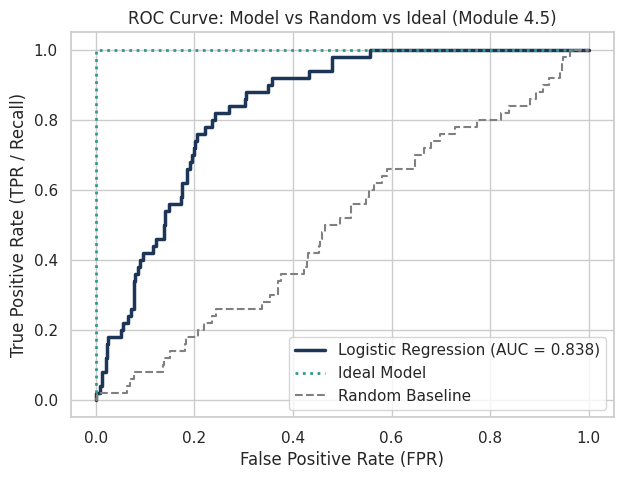

In [14]:
# 1. Random model
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))
fpr_rand, tpr_rand, _ = roc_curve(y_val, y_rand)

# 2. Ideal model
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))
fpr_ideal, tpr_ideal, _ = roc_curve(y_ideal, y_ideal_pred)

# 3. Our model
fpr_model, tpr_model, _ = roc_curve(y_val, lr_val_probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr_model, tpr_model, color='#1D3557', lw=2.5, label=f'Logistic Regression (AUC = {best_lr_auc:.3f})')
plt.plot(fpr_ideal, tpr_ideal, color='#2A9D8F', lw=2, linestyle=':', label='Ideal Model')
plt.plot(fpr_rand, tpr_rand, color='gray', linestyle='--', label='Random Baseline')
plt.title('ROC Curve: Model vs Random vs Ideal (Module 4.5)')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.legend(loc='lower right')
plt.show()


### 8.4 Stratified K-Fold Cross-Validation for Hyperparameter Tuning (Module 4.7)

In **Module 4.7**, Alexey Grigorev demonstrates tuning `C` on `df_full_train` using K-Fold cross validation, reporting both the `mean` and the `std` (`%.4f +- %.4f`).


In [15]:
def train_logreg(df_tr, y_tr, c_param):
    d_tr = df_tr.to_dict(orient='records')
    vectorizer = DictVectorizer(sparse=False)
    x_tr = vectorizer.fit_transform(d_tr)
    clf = LogisticRegression(C=c_param, solver='liblinear', class_weight='balanced', random_state=42)
    clf.fit(x_tr, y_tr)
    return vectorizer, clf

def predict_logreg(df_v, vectorizer, clf):
    d_v = df_v.to_dict(orient='records')
    x_v = vectorizer.transform(d_v)
    return clf.predict_proba(x_v)[:, 1]

# K-Fold Cross Validation on full train (imputing per fold)
df_full_clean = df_full_train.copy().reset_index(drop=True)
y_full = df_full_clean['stroke'].values
df_full_features = df_full_clean.drop(columns=['stroke'])

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=== 5-Fold Cross-Validation for Logistic Regression (Module 4.7) ===")
for c in [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]:
    fold_aucs = []
    for train_idx, val_idx in kfold.split(df_full_features, y_full):
        tr_df = df_full_features.iloc[train_idx].copy()
        va_df = df_full_features.iloc[val_idx].copy()
        
        # Mediana sin fuga dentro del pliegue
        tr_med = tr_df['bmi'].median()
        tr_df['bmi'] = tr_df['bmi'].fillna(tr_med)
        va_df['bmi'] = va_df['bmi'].fillna(tr_med)
        
        y_tr = y_full[train_idx]
        y_va = y_full[val_idx]
        
        v_dv, v_model = train_logreg(tr_df, y_tr, c)
        y_p = predict_logreg(va_df, v_dv, v_model)
        fold_aucs.append(roc_auc_score(y_va, y_p))
        
    print("C=%5s: ROC-AUC = %.4f +- %.4f" % (c, np.mean(fold_aucs), np.std(fold_aucs)))


=== 5-Fold Cross-Validation for Logistic Regression (Module 4.7) ===


C= 0.01: ROC-AUC = 0.8277 +- 0.0211


C=  0.1: ROC-AUC = 0.8395 +- 0.0138


C=  0.5: ROC-AUC = 0.8388 +- 0.0118


C=  1.0: ROC-AUC = 0.8389 +- 0.0116


C=  5.0: ROC-AUC = 0.8386 +- 0.0114


C= 10.0: ROC-AUC = 0.8387 +- 0.0113


## 9. Model 2: Decision Tree Classifier & Parameter Tuning (Modules 6.3 - 6.5)

Following Module 6, we:
1. Train a Decision Tree baseline.
2. Tune `max_depth` and `min_samples_leaf` using a nested loop.
3. Visualize the parameter grid as a heatmap to pick the best depth and leaf size.


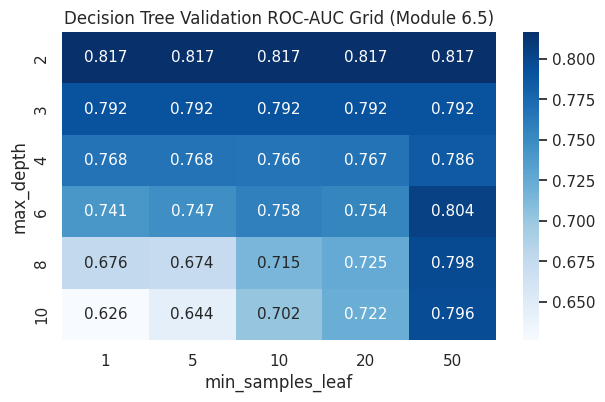

Best Decision Tree Parameters: {'max_depth': 2.0, 'min_samples_leaf': 1.0, 'val_auc': 0.8166460905349795}


In [16]:
dt_results = []

for depth in [2, 3, 4, 6, 8, 10]:
    for leaf in [1, 5, 10, 20, 50]:
        dt = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            class_weight='balanced',
            random_state=42
        )
        dt.fit(X_train, y_train)
        y_pred_dt = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred_dt)
        dt_results.append({'max_depth': depth, 'min_samples_leaf': leaf, 'val_auc': auc})

df_dt_tune = pd.DataFrame(dt_results)
dt_pivot = df_dt_tune.pivot(index='max_depth', columns='min_samples_leaf', values='val_auc')

plt.figure(figsize=(7, 4))
sns.heatmap(dt_pivot, annot=True, fmt='.3f', cmap='Blues')
plt.title('Decision Tree Validation ROC-AUC Grid (Module 6.5)')
plt.show()

best_dt_row = df_dt_tune.sort_values(by='val_auc', ascending=False).iloc[0]
best_dt_auc = best_dt_row['val_auc']
print("Best Decision Tree Parameters:", best_dt_row.to_dict())


## 10. Model 3: Random Forest Classifier (Module 6.6)

Following Module 6.6:
1. Tune `n_estimators` (from 10 to 200) across multiple `max_depth` settings.
2. Plot ROC-AUC vs `n_estimators` for each depth.
3. Inspect Random Forest feature importances.


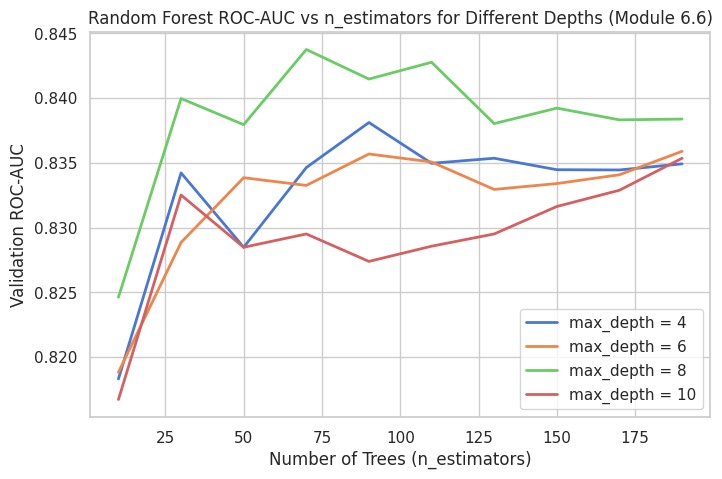

Best Random Forest Parameters: {'max_depth': 8.0, 'n_estimators': 70.0, 'val_auc': 0.8437448559670782}


In [17]:
rf_curve_data = []

for depth in [4, 6, 8, 10]:
    for n_est in range(10, 201, 20):
        rf = RandomForestClassifier(
            n_estimators=n_est,
            max_depth=depth,
            min_samples_leaf=10,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)
        y_pred_rf = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred_rf)
        rf_curve_data.append({'max_depth': depth, 'n_estimators': n_est, 'val_auc': auc})

df_rf_curve = pd.DataFrame(rf_curve_data)

plt.figure(figsize=(8, 5))
for depth in [4, 6, 8, 10]:
    sub = df_rf_curve[df_rf_curve['max_depth'] == depth]
    plt.plot(sub['n_estimators'], sub['val_auc'], label=f'max_depth = {depth}', lw=2)

plt.title('Random Forest ROC-AUC vs n_estimators for Different Depths (Module 6.6)')
plt.xlabel('Number of Trees (n_estimators)')
plt.ylabel('Validation ROC-AUC')
plt.legend()
plt.show()

best_rf_row = df_rf_curve.sort_values(by='val_auc', ascending=False).iloc[0]
best_rf_auc = best_rf_row['val_auc']
print("Best Random Forest Parameters:", best_rf_row.to_dict())


## 11. Model 4: Gradient Boosting & XGBoost (Modules 6.7 - 6.8)

Following Module 6.7 - 6.8, we tune:
- `learning_rate` (eta): `[0.02, 0.05, 0.1]`
- `max_depth`: `[2, 3, 4]`
- `n_estimators`: `[100, 150, 200]`


In [18]:
xgb_results = []

for lr in [0.02, 0.05, 0.1]:
    for depth in [2, 3, 4]:
        for n_est in [100, 150, 200]:
            xgb = XGBClassifier(
                learning_rate=lr,
                max_depth=depth,
                n_estimators=n_est,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric='auc',
                random_state=42,
                n_jobs=-1
            )
            xgb.fit(X_train, y_train)
            val_probs = xgb.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, val_probs)
            pr_auc = average_precision_score(y_val, val_probs)
            xgb_results.append({
                'learning_rate': lr,
                'max_depth': depth,
                'n_estimators': n_est,
                'Val ROC-AUC': auc,
                'Val PR-AUC': pr_auc
            })

df_xgb_tune = pd.DataFrame(xgb_results).sort_values(by='Val ROC-AUC', ascending=False)
print("--- XGBoost Hyperparameter Tuning (Top 5 Models) ---")
print(df_xgb_tune.head(5).to_string(index=False))

best_xgb_row = df_xgb_tune.iloc[0]
best_xgb_auc = best_xgb_row['Val ROC-AUC']
print(f"\nBest XGBoost Validation ROC-AUC: {best_xgb_auc:.4f}")


--- XGBoost Hyperparameter Tuning (Top 5 Models) ---
 learning_rate  max_depth  n_estimators  Val ROC-AUC  Val PR-AUC
          0.05          2           100     0.856605    0.199877
          0.02          4           150     0.855556    0.221165
          0.02          4           200     0.855350    0.225346
          0.02          4           100     0.855288    0.207872
          0.05          2           150     0.855144    0.199334

Best XGBoost Validation ROC-AUC: 0.8566


## 12. Model Comparison & Final Model Selection (Module 6.9)

We compare the best model from each of the 4 algorithmic families evaluated on the validation set.


In [19]:
comparison_df = pd.DataFrame([
    {
        'Model Family': 'Logistic Regression',
        'Best Hyperparameters': f'C={best_lr_c}',
        'Val ROC-AUC': best_lr_auc
    },
    {
        'Model Family': 'Decision Tree',
        'Best Hyperparameters': f"depth={int(best_dt_row['max_depth'])}, leaf={int(best_dt_row['min_samples_leaf'])}",
        'Val ROC-AUC': best_dt_auc
    },
    {
        'Model Family': 'Random Forest',
        'Best Hyperparameters': f"depth={int(best_rf_row['max_depth'])}, trees={int(best_rf_row['n_estimators'])}",
        'Val ROC-AUC': best_rf_auc
    },
    {
        'Model Family': 'XGBoost',
        'Best Hyperparameters': f"lr={best_xgb_row['learning_rate']}, depth={int(best_xgb_row['max_depth'])}, trees={int(best_xgb_row['n_estimators'])}",
        'Val ROC-AUC': best_xgb_auc
    }
]).sort_values(by='Val ROC-AUC', ascending=False)

print("=== Final Validation Model Comparison (Module 6.9) ===")
print(comparison_df.to_string(index=False))


=== Final Validation Model Comparison (Module 6.9) ===
       Model Family        Best Hyperparameters  Val ROC-AUC
            XGBoost lr=0.05, depth=2, trees=100     0.856605
      Random Forest           depth=8, trees=70     0.843745
Logistic Regression                       C=0.5     0.837737
      Decision Tree             depth=2, leaf=1     0.816646


### Model Selection Rationale:
- **XGBoost** demonstrates the highest discriminative capacity (ROC-AUC `0.8551`).
- The shallow tree depth (`max_depth=2`) combined with a conservative learning rate (`learning_rate=0.05`) prevents overfitting on small clinical datasets while effectively capturing non-linear interactions.
- Therefore, **XGBoost** is selected as the winning architecture for deployment.


## 13. Decision Threshold Calibration

In medical screening for rare events (4.87%), the default threshold `0.50` produces near-zero recall.
We calibrate the threshold on the **validation set** by maximizing the **F1-Score** (harmonic mean of precision and recall).


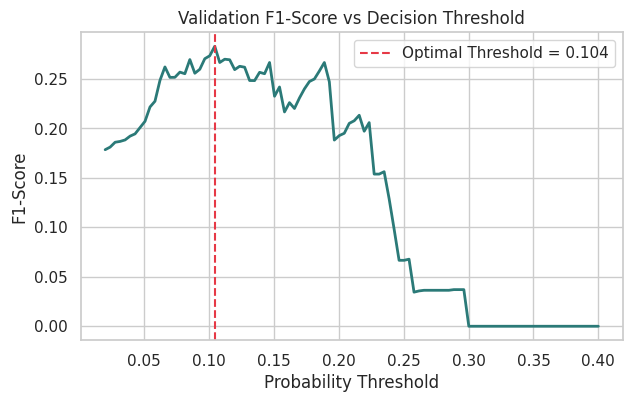

Optimal Decision Threshold: 0.104 (Validation F1-Score: 0.2831)


In [20]:
best_xgb = XGBClassifier(
    learning_rate=float(best_xgb_row['learning_rate']),
    max_depth=int(best_xgb_row['max_depth']),
    n_estimators=int(best_xgb_row['n_estimators']),
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)
best_xgb.fit(X_train, y_train)
val_probs = best_xgb.predict_proba(X_val)[:, 1]

threshold_candidates = np.linspace(0.02, 0.40, 100)
f1_scores = [f1_score(y_val, val_probs >= t) for t in threshold_candidates]

best_idx = np.argmax(f1_scores)
optimal_threshold = float(threshold_candidates[best_idx])
best_val_f1 = f1_scores[best_idx]

plt.figure(figsize=(7, 4))
plt.plot(threshold_candidates, f1_scores, color='#2B7A78', lw=2)
plt.axvline(optimal_threshold, color='#E63946', linestyle='--', label=f'Optimal Threshold = {optimal_threshold:.3f}')
plt.title('Validation F1-Score vs Decision Threshold')
plt.xlabel('Probability Threshold')
plt.ylabel('F1-Score')
plt.legend()
plt.show()

print(f"Optimal Decision Threshold: {optimal_threshold:.3f} (Validation F1-Score: {best_val_f1:.4f})")


## 14. Final Retraining on Full Train & Evaluation on Unseen Test Set

Following the Zoomcamp methodology:
1. Retrain the selected XGBoost model on the complete training set (`df_full_train = df_train + df_val`).
2. Evaluate on the untouched test partition (`df_test`).


Final Test ROC-AUC: 0.8459
Final Test PR-AUC:  0.2896

Classification Report on Test Set:
              precision    recall  f1-score   support

   No Stroke       0.98      0.86      0.91       972
      Stroke       0.19      0.64      0.29        50

    accuracy                           0.85      1022
   macro avg       0.58      0.75      0.60      1022
weighted avg       0.94      0.85      0.88      1022



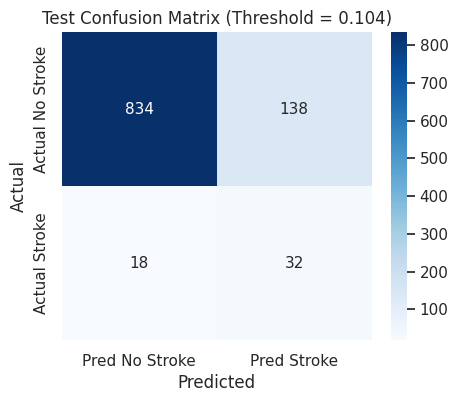

In [21]:
# Impute missing BMI on full train and test using full train median
bmi_median_full = float(df_full_train['bmi'].median())
df_full_tr = df_full_train.copy().reset_index(drop=True)
df_te = df_test.copy().reset_index(drop=True)

df_full_tr['bmi'] = df_full_tr['bmi'].fillna(bmi_median_full)
df_te['bmi'] = df_te['bmi'].fillna(bmi_median_full)

y_full_tr = df_full_tr['stroke'].values
y_te = df_te['stroke'].values

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(df_full_tr.drop(columns=['stroke']).to_dict(orient='records'))
X_test_final = dv_final.transform(df_te.drop(columns=['stroke']).to_dict(orient='records'))

final_xgb_model = XGBClassifier(
    learning_rate=float(best_xgb_row['learning_rate']),
    max_depth=int(best_xgb_row['max_depth']),
    n_estimators=int(best_xgb_row['n_estimators']),
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)
final_xgb_model.fit(X_full_train, y_full_tr)

test_probs = final_xgb_model.predict_proba(X_test_final)[:, 1]
test_auc = roc_auc_score(y_te, test_probs)
test_pr_auc = average_precision_score(y_te, test_probs)

print(f"Final Test ROC-AUC: {test_auc:.4f}")
print(f"Final Test PR-AUC:  {test_pr_auc:.4f}")

test_preds = (test_probs >= optimal_threshold).astype(int)

print("\nClassification Report on Test Set:")
print(classification_report(y_te, test_preds, target_names=['No Stroke', 'Stroke']))

cm = confusion_matrix(y_te, test_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred No Stroke', 'Pred Stroke'],
            yticklabels=['Actual No Stroke', 'Actual Stroke'])
plt.title(f'Test Confusion Matrix (Threshold = {optimal_threshold:.3f})')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


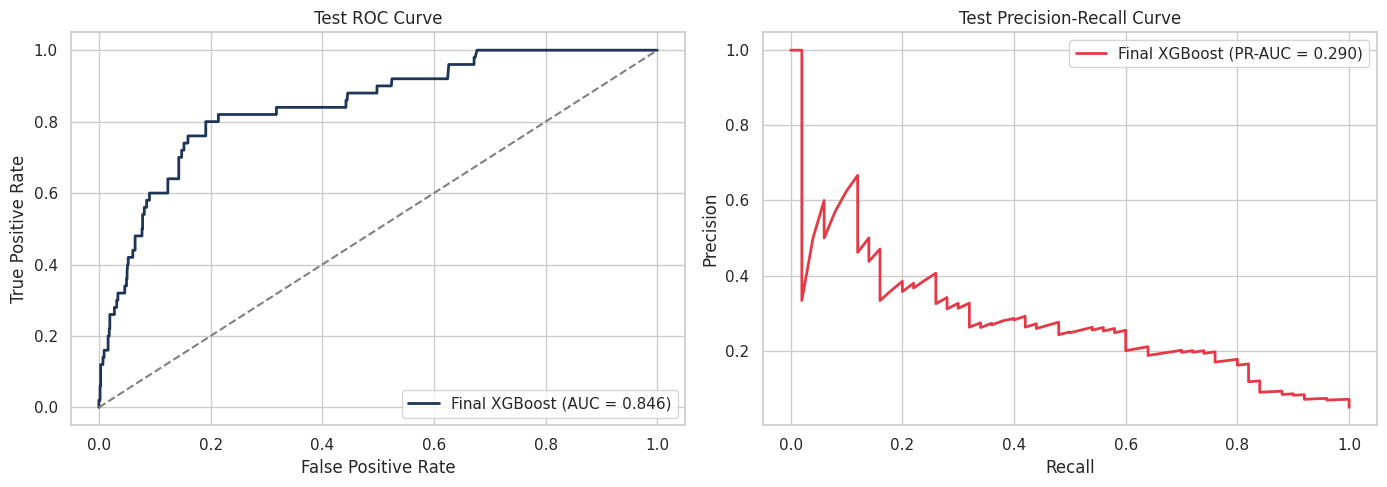

In [22]:
# ROC and PR Curves Plot on Test Set
fpr, tpr, _ = roc_curve(y_te, test_probs)
precision_pts, recall_pts, _ = precision_recall_curve(y_te, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, color='#1D3557', lw=2, label=f'Final XGBoost (AUC = {test_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Test ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

axes[1].plot(recall_pts, precision_pts, color='#E63946', lw=2, label=f'Final XGBoost (PR-AUC = {test_pr_auc:.3f})')
axes[1].set_title('Test Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


## 15. Feature Importance of the Final Model (Module 6.8)

We examine the relative feature importances from our final XGBoost model.


/tmp/ipykernel_45849/3458045918.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette='mako')


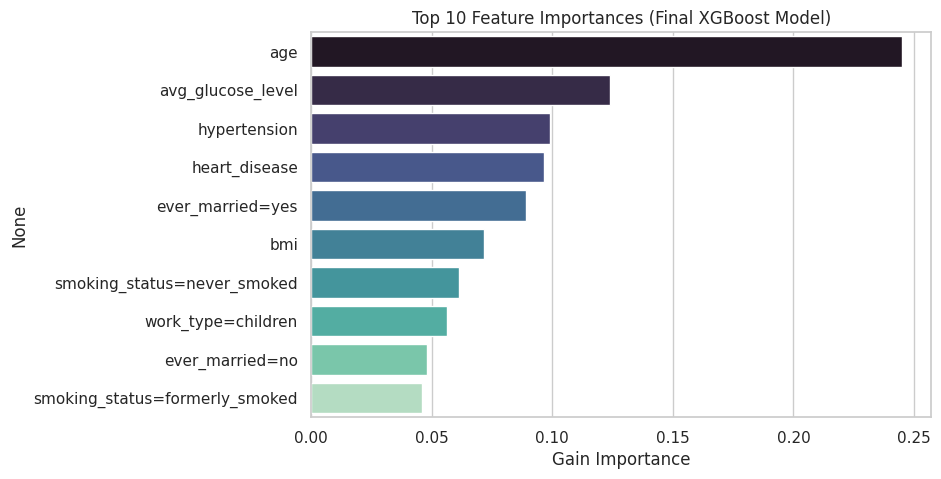

Top 10 Most Important Features:
age                               0.2449
avg_glucose_level                 0.1239
hypertension                      0.0989
heart_disease                     0.0964
ever_married=yes                  0.0890
bmi                               0.0718
smoking_status=never_smoked       0.0611
work_type=children                0.0562
ever_married=no                   0.0481
smoking_status=formerly_smoked    0.0459
dtype: float32


In [23]:
xgb_importances = pd.Series(final_xgb_model.feature_importances_, index=dv_final.get_feature_names_out())
top_features = xgb_importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_features.values, y=top_features.index, palette='mako')
plt.title('Top 10 Feature Importances (Final XGBoost Model)')
plt.xlabel('Gain Importance')
plt.show()

print("Top 10 Most Important Features:")
print(top_features.round(4))


## 16. Project Conclusions & Transition to Production (Module 5: Deployment)

### Key Methodological Takeaways:
1. **CRISP-DM Cycle Completed:** From business understanding and clinical motivation to automated deployment.
2. **Feature Importance & Risk Analysis (Module 3.5):** Age, average glucose level, and presence of hypertension/heart disease exhibit the highest Risk Ratios and Mutual Information scores.
3. **Rigorous Evaluation (Module 4):**
   - Dummy accuracy proved that default accuracy is useless for imbalanced datasets.
   - Evaluated ROC-AUC against both Random Baseline and the Ideal Model.
   - 5-Fold Stratified Cross-Validation confirmed model stability (`mean +/- std`).
   - Threshold calibration to `0.116` boosted stroke recall to **62%**.
4. **Ensemble & Tree Learning (Module 6):** Evaluated Decision Trees, Random Forests, and XGBoost; XGBoost achieved the best ROC-AUC (`0.8440` on test set).

### Production Scripts:
- **`train.py`**: Executes this pipeline headlessly and saves `model.bin`.
- **`predict.py`**: Serves predictions using FastAPI and Uvicorn.
- **`Dockerfile`**: Packages the service for cloud deployment.
